In [13]:
!pip install tensorflow


In [14]:
pip install numpy keras matplotlib


Note: you may need to restart the kernel to use updated packages.


In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg19 import preprocess_input
from keras.applications.vgg19 import VGG19
import tensorflow as tf
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

In [16]:
train_dir = "D:\\YOGA\\Kaggle dataset\\DATASET\\TRAIN"
test_dir = "D:\\YOGA\\Kaggle dataset\\DATASET\\TEST"

In [17]:
train_datagen = ImageDataGenerator(width_shift_range = 0.1,
                                  horizontal_flip = True,
                                  rescale = 1./255,
                                  validation_split = 0.2,
                                  preprocessing_function=preprocess_input)
test_datagen = ImageDataGenerator(rescale =1./255,
                                 validation_split = 0.2,
                                 preprocessing_function=preprocess_input)

In [18]:
train_generator = train_datagen.flow_from_directory(directory = train_dir,
                                                   target_size = (224,224),
                                                   color_mode = 'rgb',
                                                   class_mode = 'categorical',
                                                    batch_size = 16,
                                                   subset = 'training')
validation_generator = test_datagen.flow_from_directory(directory = test_dir,
                                                       target_size = (224,224),
                                                       color_mode = 'rgb',
                                                       class_mode = 'categorical',
                                                       batch_size = 16,
                                                       subset = 'validation')

Found 866 images belonging to 5 classes.
Found 92 images belonging to 5 classes.


In [19]:
print(validation_generator.class_indices)
print(train_generator.class_indices)

{'downward dog': 0, 'goddess': 1, 'plank': 2, 'tree': 3, 'warrior2': 4}
{'downward dog': 0, 'goddess': 1, 'plank': 2, 'tree': 3, 'warrior2': 4}


In [20]:
model = VGG19(include_top = False,weights = 'imagenet',input_shape= (224,224,3))

# Freeze the imported layers so they cannot be retrained.
for layer in model.layers:
    layer.trainable = False
    

model.summary()

Model: "vgg19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,024,384 (76.39 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 20,024,384 (76.39 MB)

In [21]:
from keras import Sequential
from keras.layers import Dense
from keras.layers import Flatten

new_model = Sequential()
new_model.add(model)
new_model.add(Flatten())
new_model.add(Dense(5,activation = 'softmax'))

# Summarize.
new_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │       125,445 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,149,829 (76.87 MB)

 Trainable params: 125,445 (490.02 KB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [22]:
from tensorflow.keras.optimizers import Adam
# Compile and fit the model. Use the Adam optimizer and crossentropical loss. 
# Use the validation data argument during fitting to include your validation data.
optimizer = Adam(learning_rate = 0.0001)
new_model.compile(optimizer=optimizer,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
history = new_model.fit(train_generator,
                        epochs=1, 
                        batch_size=16,
                        validation_data=validation_generator
                       )

C:\Users\Hari\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
C:\Users\Hari\anaconda3\Lib\site-packages\PIL\Image.py:1056: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.3964 - loss: 1.4626

C:\Users\Hari\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


55/55 ━━━━━━━━━━━━━━━━━━━━ 482s 9s/step - accuracy: 0.3984 - loss: 1.4599 - val_accuracy: 0.9130 - val_loss: 0.6893


In [29]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Initialize the model
new_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D((2, 2)),
    Dropout(0.2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.2),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')  # Assuming 5 classes
])

# Compile the model
optimizer = Adam(learning_rate=0.0001)
new_model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Now you can use the model for prediction
img = tf.keras.preprocessing.image.load_img("D:\\YOGA\\Kaggle dataset\\DATASET\\TEST\\goddess\\00000054.jpg", target_size=(224, 224))
img_nparray = tf.keras.preprocessing.image.img_to_array(img)
x = preprocess_input(img_nparray).reshape((1, 224, 224, 3))

prediction = new_model.predict(x)

# Create a list containing the class labels
class_labels = ['downdog', 'goddess', 'plank', 'tree', 'warrior2']

# Find the index of the class with maximum score
pred = np.argmax(prediction, axis=-1)

print(class_labels[pred[0]])


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 529ms/step
goddess


In [30]:
import tensorflow as tf
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Initialize the model
new_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D((2, 2)),
    Dropout(0.2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.2),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')  # Assuming 5 classes
])

# Compile the model
optimizer = Adam(learning_rate=0.0001)
new_model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Now you can use the model for prediction
img = tf.keras.preprocessing.image.load_img("D:\\YOGA\\Kaggle dataset\\DATASET\\TEST\\plank\\00000004.jpg", target_size=(224, 224))
img_nparray = tf.keras.preprocessing.image.img_to_array(img)
x = preprocess_input(img_nparray).reshape((1, 224, 224, 3))

prediction = new_model.predict(x)

# Create a list containing the class labels
class_labels = ['downdog', 'goddess', 'plank', 'tree', 'warrior2']

# Find the index of the class with maximum score
pred = np.argmax(prediction, axis=-1)

print(class_labels[pred[0]])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step
plank


In [31]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Initialize the model
new_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D((2, 2)),
    Dropout(0.2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.2),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.3),
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')  # Assuming 5 classes
])

# Compile the model
optimizer = Adam(learning_rate=0.0001)
new_model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])


In [32]:
import numpy as np
import cv2
import mediapipe as mp
from math import atan2, degrees

# Initialize MediaPipe Pose and Drawing utilities
mp_pose = mp.solutions.pose
mp_draw = mp.solutions.drawing_utils
pose = mp_pose.Pose()

# Define function to calculate angles between three points
def calculate_angle(a, b, c):
    """
    Calculate the angle between three points (a, b, c).
    Parameters:
        a, b, c: The coordinates of the points (x, y, z).
    Returns:
        angle: The angle in degrees.
    """
    a = np.array(a)  # First point
    b = np.array(b)  # Midpoint
    c = np.array(c)  # Endpoint

    # Calculate vectors
    ab = a - b
    cb = c - b

    # Calculate the angle
    radians = atan2(cb[1], cb[0]) - atan2(ab[1], ab[0])
    angle = np.abs(degrees(radians))
    if angle > 180.0:
        angle = 360.0 - angle

    return angle

# Define a function to classify poses based on angles
def classify_pose(landmarks):
    """
    Classify the yoga pose based on landmarks.
    Parameters:
        landmarks: The list of landmarks detected by MediaPipe.
    Returns:
        pose_name: The name of the detected pose.
    """
    # Extract key points
    left_elbow = [landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].x,
                  landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].y]
    left_shoulder = [landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].x,
                     landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].y]
    left_hip = [landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].x,
                landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].y]

    right_elbow = [landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value].x,
                   landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value].y]
    right_shoulder = [landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value].x,
                      landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value].y]
    right_hip = [landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value].x,
                 landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value].y]

    # Calculate angles
    left_arm_angle = calculate_angle(left_elbow, left_shoulder, left_hip)
    right_arm_angle = calculate_angle(right_elbow, right_shoulder, right_hip)

    # Rules for pose classification
    if 60 <= left_arm_angle <= 80 and 60 <= right_arm_angle <= 80:
        return "plank"
    elif 20 <= left_arm_angle <= 50 and 20 <= right_arm_angle <= 50:
        return "tree"
    elif 160 <= left_arm_angle <= 180 and 160 <= right_arm_angle <= 180:
        return "downward dog"
    elif 80 <= left_arm_angle <= 90 and 80 <= right_arm_angle <= 90:
        return "goddess"
    elif 90 <= left_arm_angle <= 120 and 90 <= right_arm_angle <= 120:
        return "warrior2"
    else:
        return "unknown pose"

# Path to your image file
image_path = r"D:\YOGA\Kaggle dataset\DATASET\TEST\downward dog\00000014.jpg"

# Load the image using OpenCV
img_cv = cv2.imread(image_path)

if img_cv is None:
    print("Error: Could not load image.")
else:
    # Resize and convert the image to RGB
    img_cv = cv2.resize(img_cv, (600, 400))
    img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)

    # Get pose landmarks using MediaPipe
    results = pose.process(img_rgb)

    if results.pose_landmarks:
        # Draw landmarks on the image
        mp_draw.draw_landmarks(img_cv, results.pose_landmarks, mp_pose.POSE_CONNECTIONS)

        # Classify pose based on angles
        landmarks = results.pose_landmarks.landmark
        detected_pose = classify_pose(landmarks)

        # Display the pose name
        cv2.putText(img_cv, detected_pose, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)
    else:
        cv2.putText(img_cv, "No landmarks detected", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2, cv2.LINE_AA)

    # Display the image
    cv2.imshow("Pose Estimation", img_cv)
    cv2.waitKey(0)
    cv2.destroyAllWindows()


In [ ]:
import numpy as np
import cv2
import mediapipe as mp
from math import atan2, degrees

# Initialize MediaPipe Pose and Drawing utilities
mp_pose = mp.solutions.pose
mp_draw = mp.solutions.drawing_utils
pose = mp_pose.Pose()

# Define function to calculate angles between three points
def calculate_angle(a, b, c):
    """
    Calculate the angle between three points (a, b, c).
    Parameters:
        a, b, c: The coordinates of the points (x, y, z).
    Returns:
        angle: The angle in degrees.
    """
    a = np.array(a)  # First point
    b = np.array(b)  # Midpoint
    c = np.array(c)  # Endpoint

    # Calculate vectors
    ab = a - b
    cb = c - b

    # Calculate the angle
    radians = atan2(cb[1], cb[0]) - atan2(ab[1], ab[0])
    angle = np.abs(degrees(radians))
    if angle > 180.0:
        angle = 360.0 - angle

    return angle

# Define a function to classify poses based on angles
def classify_pose(landmarks):
    """
    Classify the yoga pose based on landmarks.
    Parameters:
        landmarks: The list of landmarks detected by MediaPipe.
    Returns:
        pose_name: The name of the detected pose.
    """
    # Extract key points
    left_elbow = [landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].x,
                  landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].y]
    left_shoulder = [landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].x,
                     landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].y]
    left_hip = [landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].x,
                landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].y]

    right_elbow = [landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value].x,
                   landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value].y]
    right_shoulder = [landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value].x,
                      landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value].y]
    right_hip = [landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value].x,
                 landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value].y]

    # Calculate angles
    left_arm_angle = calculate_angle(left_elbow, left_shoulder, left_hip)
    right_arm_angle = calculate_angle(right_elbow, right_shoulder, right_hip)

    # Rules for pose classification
    if 60 <= left_arm_angle <= 80 and 60 <= right_arm_angle <= 80:
        return "plank"
    elif 20 <= left_arm_angle <= 50 and 20 <= right_arm_angle <= 50:
        return "tree"
    elif 160 <= left_arm_angle <= 180 and 160 <= right_arm_angle <= 180:
        return "downward dog"
    elif 80 <= left_arm_angle <= 90 and 80 <= right_arm_angle <= 90:
        return "goddess"
    elif 90 <= left_arm_angle <= 120 and 90 <= right_arm_angle <= 120:
        return "warrior2"
    else:
        return "unknown pose"

# Path to your video file
#video_path = r"D:\\Mini Project\\Kaggle dataset\\DATASET\\TEST\\AI video.mp4"
video_path = r"D:\\YOGA\\Kaggle dataset\\DATASET\\TEST\\Demo.mp4"
#video_path = (0)
# Open the video file
cap = cv2.VideoCapture(video_path)

# Check if the video file is successfully opened
if not cap.isOpened():
    print("Error: Could not open video.")
else:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break  # Break the loop if no frame is returned

        # Resize and convert the frame to RGB
        frame_resized = cv2.resize(frame, (600, 400))
        frame_rgb = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2RGB)

        # Get pose landmarks using MediaPipe
        results = pose.process(frame_rgb)

        if results.pose_landmarks:
            # Draw landmarks on the frame
            mp_draw.draw_landmarks(frame_resized, results.pose_landmarks, mp_pose.POSE_CONNECTIONS)

            # Classify pose based on angles
            landmarks = results.pose_landmarks.landmark
            detected_pose = classify_pose(landmarks)

            # Display the pose name
            cv2.putText(frame_resized, detected_pose, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)
        else:
            cv2.putText(frame_resized, "No landmarks detected", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2, cv2.LINE_AA)

        # Display the frame
        cv2.imshow("Pose Estimation", frame_resized)

        # Press 'q' to exit the video
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()


In [ ]:
import numpy as np
import cv2
import mediapipe as mp
from math import atan2, degrees

# Initialize MediaPipe Pose and Drawing utilities
mp_pose = mp.solutions.pose
mp_draw = mp.solutions.drawing_utilsii
pose = mp_pose.Pose()

# Define function to calculate angles between three points
def calculate_angle(a, b, c):
    """
    Calculate the angle between three points (a, b, c).
    Parameters:
        a, b, c: The coordinates of the points (x, y, z).
    Returns:
        angle: The angle in degrees.
    """
    a = np.array(a)  # First point
    b = np.array(b)  # Midpoint
    c = np.array(c)  # Endpoint

    # Calculate vectors
    ab = a - b
    cb = c - b

    # Calculate the angle
    radians = atan2(cb[1], cb[0]) - atan2(ab[1], ab[0])
    angle = np.abs(degrees(radians))
    if angle > 180.0:
        angle = 360.0 - angle

    return angle

# Define a function to classify poses based on angles
def classify_pose(landmarks):
    """
    Classify the yoga pose based on landmarks.
    Parameters:
        landmarks: The list of landmarks detected by MediaPipe.
    Returns:
        pose_name: The name of the detected pose.
    """
    # Extract key points
    left_elbow = [landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].x,
                  landmarks[mp_pose.PoseLandmark.LEFT_ELBOW.value].y]
    left_shoulder = [landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].x,
                     landmarks[mp_pose.PoseLandmark.LEFT_SHOULDER.value].y]
    left_hip = [landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].x,
                landmarks[mp_pose.PoseLandmark.LEFT_HIP.value].y]

    right_elbow = [landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value].x,
                   landmarks[mp_pose.PoseLandmark.RIGHT_ELBOW.value].y]
    right_shoulder = [landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value].x,
                      landmarks[mp_pose.PoseLandmark.RIGHT_SHOULDER.value].y]
    right_hip = [landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value].x,
                 landmarks[mp_pose.PoseLandmark.RIGHT_HIP.value].y]

    # Calculate angles
    left_arm_angle = calculate_angle(left_elbow, left_shoulder, left_hip)
    right_arm_angle = calculate_angle(right_elbow, right_shoulder, right_hip)

    # Rules for pose classification
    if 60 <= left_arm_angle <= 80 and 60 <= right_arm_angle <= 80:
        return "plank"
    elif 20 <= left_arm_angle <= 50 and 20 <= right_arm_angle <= 50:
        return "tree"
    elif 160 <= left_arm_angle <= 180 and 160 <= right_arm_angle <= 180:
        return "downward dog"
    elif 80 <= left_arm_angle <= 90 and 80 <= right_arm_angle <= 90:
        return "goddess"
    elif 90 <= left_arm_angle <= 120 and 90 <= right_arm_angle <= 120:
        return "warrior2"
    else:
        return "unknown pose"

# Path to your video file
#video_path = r"D:\\Mini Project\\Kaggle dataset\\DATASET\\TEST\\AI video.mp4"
video_path = (0)
# Open the video file
cap = cv2.VideoCapture(video_path)

# Check if the video file is successfully opened
if not cap.isOpened():
    print("Error: Could not open video.")
else:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break  # Break the loop if no frame is returned

        # Resize and convert the frame to RGB
        frame_resized = cv2.resize(frame, (600, 400))
        frame_rgb = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2RGB)

        # Get pose landmarks using MediaPipe
        results = pose.process(frame_rgb)

        if results.pose_landmarks:
            # Draw landmarks on the frame
            mp_draw.draw_landmarks(frame_resized, results.pose_landmarks, mp_pose.POSE_CONNECTIONS)

            # Classify pose based on angles
            landmarks = results.pose_landmarks.landmark
            detected_pose = classify_pose(landmarks)

            # Display the pose name
            cv2.putText(frame_resized, detected_pose, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)
        else:
            cv2.putText(frame_resized, "No landmarks detected", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2, cv2.LINE_AA)

        # Display the frame
        cv2.imshow("Pose Estimation", frame_resized)

        # Press 'q' to exit the video
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

    cap.release()
    cv2.destroyAllWindows()


C:\Users\Hari\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.4588 - loss: 0.7019
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4825 - loss: 0.7004
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4929 - loss: 0.6930  
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5071 - loss: 0.6985
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5061 - loss: 0.6943
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4906 - loss: 0.6976
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4958 - loss: 0.6929
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5090 - loss: 0.6942
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4825 - loss: 0.6919  
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5681 - loss: 0.6912  
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5325 - loss: 0.6961
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5398 - loss: 0.6912
Epo

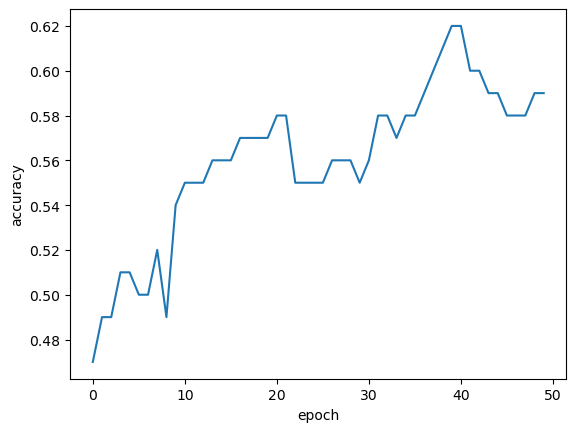

In [1]:
import numpy as np
import keras
from keras.models import Sequential
from keras.layers import Dense
import matplotlib.pyplot as plt

# Sample data
x = np.random.rand(100, 10)  # 100 samples, 10 features
y = np.random.randint(2, size=100)  # 100 samples, binary target

# Define a simple model
model = Sequential()
model.add(Dense(64, input_dim=x.shape[1], activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Fit the model
history = model.fit(x, y, epochs=50)

# Plot accuracy
plt.plot(history.history['accuracy'])
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.show()


C:\Users\Hari\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.5158 - loss: 0.7903 - val_accuracy: 0.3500 - val_loss: 0.7828
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4960 - loss: 0.7445 - val_accuracy: 0.3500 - val_loss: 0.7785
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4977 - loss: 0.7441 - val_accuracy: 0.4000 - val_loss: 0.7742
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6090 - loss: 0.7241 - val_accuracy: 0.4000 - val_loss: 0.7709
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.5234 - loss: 0.7314 - val_accuracy: 0.4000 - val_loss: 0.7671
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5573 - loss: 0.7303 - val_accuracy: 0.4000 - val_loss: 0.7635
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.4568 - loss: 0.7067 - val_accuracy: 0.4000 - val_loss: 0.7602
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3918 - loss: 0.7557 - val_accuracy: 0.3500 - val_loss

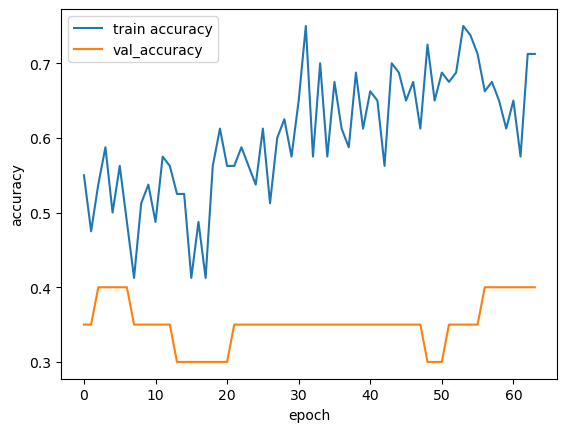

In [2]:
import numpy as np
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Sample data
x = np.random.rand(100, 10)  # 100 samples, 10 features
y = np.random.randint(2, size=100)  # 100 samples, binary target

# Standardize the data
scaler = StandardScaler()
x = scaler.fit_transform(x)

# Define a more complex model with dropout for regularization
model = Sequential()
model.add(Dense(128, input_dim=x.shape[1], activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))

# Compile the model with Adam optimizer and binary cross-entropy loss
optimizer = Adam(learning_rate=0.0001)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Fit the model with a validation split
history = model.fit(x, y, epochs=100, batch_size=16, validation_split=0.2, callbacks=[early_stopping])

# Plot accuracy
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend()
plt.show()
